# 05 · Segments (H1 to H4)

**Question:** does the H0 shift (after a make minus after a miss, distance vs the player's own baseline,
Model 3) differ by experience, usage, playstyle and season type?

Runs once on the **analysis half**. Rules: D-041 to D-044 (and playbook 6.1-6.8). The comparison
with the predictions and the Result column are Massimo's.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hothand import core, segtests as st
from hothand.config import FIGURES, PROCESSED, load_config
from hothand.features import FEATURES, SHOTS
from hothand.segments import PLAYER_SEASONS

pd.set_option("display.max_columns", 40, "display.width", 200)
cfg = load_config()
print("Python:", sys.executable)
print("pandas:", pd.__version__)
HALF = "analysis"
d = core.prepare(pd.read_parquet(FEATURES), cfg, HALF)
both = st.both_contexts(d)
CLUSTERS = ["rim_bigs", "rim_and_corner", "mid_range_scorers", "three_point_shooters"]
print(f"{len(d):,} pairs, {d.player_id.nunique():,} players, half = {HALF}")

Python: /Users/massimovitale/Desktop/nba-shot-selection-hot-hand/.venv/bin/python
pandas: 3.0.6


535,659 pairs, 1,199 players, half = analysis


## 1. The shift inside each group (display, playbook 6.1)

In [2]:
groups = [
    ("H0", "All players", pd.Series(True, index=d.index)),
    ("H1", "Rookies", d.experience_group.eq("rookie")),
    ("H1", "Veterans (10th season+)", d.experience_group.eq("veteran")),
    ("H2", "Low usage", d.usage_tier.eq("low")),
    ("H2", "Mid usage", d.usage_tier.eq("mid")),
    ("H2", "High usage", d.usage_tier.eq("high")),
    ("H2", "All-Stars (labelled subset)", d.all_star.astype(bool)),
] + [("H3", c.replace("_", " ").capitalize(), d.cluster.eq(c)) for c in CLUSTERS] + [
    ("H4", "Regular season, players in both contexts", both & d.season_type.eq("Regular Season")),
    ("H4", "Playoffs, players in both contexts", both & d.season_type.eq("Playoffs")),
    ("H4", "Regular season, all players", d.season_type.eq("Regular Season")),
    ("H4", "Playoffs, all players", d.season_type.eq("Playoffs")),
]
shifts = pd.DataFrame([{"hypothesis": h, **st.group_shift(d, cfg, label, mask)}
                       for h, label, mask in groups])
shifts.round(3)

,hypothesis,group,n_pairs,n_players,status,estimate,se,ci_low,ci_high,p_value,after_miss_vs_baseline_ft,after_make_vs_baseline_ft
0,H0,All players,535659,1199,estimated,1.495,0.068,1.362,1.628,0.0,-0.878,0.583
1,H1,Rookies,41274,730,estimated,1.559,0.125,1.314,1.805,0.0,-0.986,0.589
2,H1,Veterans (10th season+),115521,229,estimated,1.546,0.133,1.284,1.807,0.0,-0.903,0.617
3,H2,Low usage,53154,570,estimated,1.146,0.101,0.948,1.344,0.0,-0.839,0.312
4,H2,Mid usage,132768,513,estimated,1.198,0.080,1.040,1.356,0.0,-0.781,0.368
5,H2,High usage,339995,303,estimated,1.655,0.091,1.475,1.834,0.0,-0.915,0.706
6,H2,All-Stars (labelled subset),101477,76,estimated,1.797,0.187,1.425,2.169,0.0,-0.928,0.822
7,H3,Rim bigs,41029,97,estimated,0.813,0.162,0.491,1.135,0.0,-0.320,0.392
8,H3,Rim and corner,113341,238,estimated,1.601,0.131,1.344,1.858,0.0,-0.944,0.589
9,H3,Mid range scorers,134053,157,estimated,1.425,0.095,1.237,1.614,0.0,-0.790,0.610


## 2. Pre-registered tests and Holm correction (playbook 6.1, 6.4)

Each test is the difference in the shift between two groups (interaction in Model 3), in feet:
H1 = rookies minus veterans; H2 = low minus high usage; H3 = joint test across the four clusters;
H4 = playoffs minus regular season (players in both contexts; all players shown next to it).

In [3]:
h1 = st.interaction_test(d, d.experience_group.map({"rookie": 1, "veteran": 0}),
                        "H1: rookies minus veterans")
h2 = st.interaction_test(d, d.usage_tier.map({"low": 1, "high": 0}), "H2: low minus high usage")
h3 = st.joint_cluster_test(d, CLUSTERS, "three_point_shooters")
h4 = st.interaction_test(d[both], d.loc[both, "season_type"].eq("Playoffs").astype(float),
                         "H4: playoffs minus regular season (players in both contexts)")
h4_all = st.interaction_test(d, d.season_type.eq("Playoffs").astype(float),
                             "H4 companion: playoffs minus regular season (all players)")
tests = pd.DataFrame([h1, h2, {k: v for k, v in h3.items() if k != "pairwise_vs_reference"}, h4, h4_all])
holm = st.holm({"H1": h1["p_value"], "H2": h2["p_value"], "H3": h3["p_value"], "H4": h4["p_value"]},
               cfg["inference"]["alpha"])
display(tests.round(4))
holm.round(4)

,test,n_pairs,n_players,estimate,se,ci_low,ci_high,p_value,statistic
0,H1: rookies minus veterans,156795,959,0.0680,0.1762,-0.2778,0.4137,0.6997,NaN
1,H2: low minus high usage,393149,774,-0.4684,0.1312,-0.7259,-0.2109,0.0004,NaN
2,H3 joint: shift equal across clusters (referen...,425852,505,NaN,NaN,NaN,NaN,0.0000,24.5917
3,H4: playoffs minus regular season (players in ...,274222,576,-0.0773,0.1078,-0.2890,0.1344,0.4736,NaN
4,H4 companion: playoffs minus regular season (a...,535659,1199,-0.1082,0.1063,-0.3167,0.1004,0.3091,NaN


,hypothesis,p_unadjusted,p_holm,reject_at_alpha
0,H1,0.6997,0.9471,False
1,H2,0.0004,0.0011,True
2,H3,0.0000,0.0001,True
3,H4,0.4736,0.9471,False


H3 pairwise differences (each cluster minus three-point shooters) are read only if the joint test rejects after Holm.

In [4]:
h3_rejects = bool(holm.set_index("hypothesis").loc["H3", "reject_at_alpha"])
pairwise = pd.DataFrame(h3["pairwise_vs_reference"]).T
print("H3 joint test rejects after Holm:", h3_rejects)
pairwise.round(4) if h3_rejects else "not read: the joint test does not reject"

H3 joint test rejects after Holm: True


,estimate,se,ci_low,ci_high,p_value
made_x_rim_bigs,-1.0285,0.2129,-1.4468,-0.6102,0.0000
made_x_rim_and_corner,-0.2483,0.1548,-0.5525,0.0559,0.1094
made_x_mid_range_scorers,-0.4153,0.1390,-0.6884,-0.1422,0.0030


## 3. Secondary: rookie, usage and cluster interactions in one model (playbook 6.5, not a finding)

In [5]:
secondary = st.joint_secondary(d)
secondary.round(4)

,term,estimate,se,ci_low,ci_high,p_value
0,made_x_rookie,0.2696,0.1236,0.0271,0.5121,0.0294
1,made_x_veteran,0.0468,0.1330,-0.2141,0.3077,0.7252
2,made_x_usage_low,-0.2082,0.1170,-0.4378,0.0214,0.0755
3,made_x_usage_high,0.6208,0.1146,0.3959,0.8457,0.0000
4,made_x_rim_bigs,-1.0276,0.1916,-1.4035,-0.6517,0.0000
5,made_x_mid_range_scorers,-0.5339,0.1287,-0.7864,-0.2813,0.0000
6,made_x_rim_and_corner,-0.2757,0.1376,-0.5457,-0.0057,0.0453


## 4. Forest plot with the pre-registered predictions (playbook 6.8)

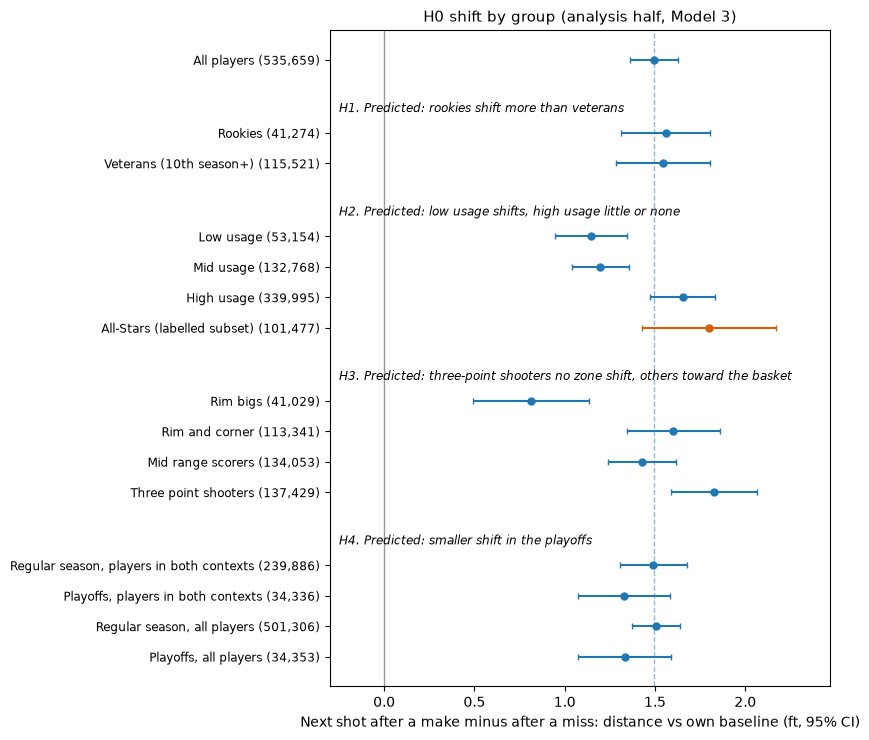

In [6]:
pred = {"H1": "Predicted: rookies shift more than veterans",
        "H2": "Predicted: low usage shifts, high usage little or none",
        "H3": "Predicted: three-point shooters no zone shift, others toward the basket",
        "H4": "Predicted: smaller shift in the playoffs"}
est = shifts[shifts.status == "estimated"].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8.5, 7.5))
y, ticks, labels = 0, [], []
for h in ["H0", "H1", "H2", "H3", "H4"]:
    block = est[est.hypothesis == h]
    if h != "H0":
        y -= 0.6
        ax.text(-0.25, y, f"{h}. {pred[h]}", fontsize=8.5, style="italic", va="center")
        y -= 0.8
    for _, r in block.iterrows():
        color = "#d95f02" if "All-Star" in r.group else "#1f77b4"
        ax.errorbar(r.estimate, y, xerr=[[r.estimate - r.ci_low], [r.ci_high - r.estimate]],
                    fmt="o", color=color, ms=5, capsize=2)
        ticks.append(y); labels.append(f"{r.group} ({r.n_pairs:,})")
        y -= 1
ax.axvline(0, color="#999", lw=1)
h0 = est.loc[est.group == "All players", "estimate"].iloc[0]
ax.axvline(h0, color="#1f77b4", lw=1, ls="--", alpha=0.5)
ax.set_yticks(ticks, labels, fontsize=8.5)
ax.set_xlabel("Next shot after a make minus after a miss: distance vs own baseline (ft, 95% CI)")
ax.set_title("H0 shift by group (analysis half, Model 3)", fontsize=11)
ax.set_xlim(-0.3, max(est.ci_high) + 0.3)
fig.tight_layout()
fig.savefig(FIGURES / "stage6_forest.png", dpi=150)

## 5. Cluster heat map: zone shares vs own baseline after a make and after a miss (playbook 6.8)

rel_restricted_area  rel_paint  rel_mid_range  rel_corner_three  rel_above_break_three
cluster              prev_made                                                                                           
rim_bigs             after a miss                 2.05      -0.44          -1.04              0.23                  -0.80
                     after a make                -1.49      -0.54           0.79             -0.24                   1.49
rim_and_corner       after a miss                 3.82       0.46          -1.09              0.08                  -3.26
                     after a make                -1.83      -0.70           0.22             -0.53                   2.83
mid_range_scorers    after a miss                 2.90       0.95          -1.45              0.43                  -2.83
                     after a make                -1.48      -1.32           0.31             -0.53                   3.02
three_point_shooters after a miss                 3.21       1.22          -0.28              0.26                  -4.41
                     after a make                -1.57      -1.35          -0.45             -0.88                   4.25

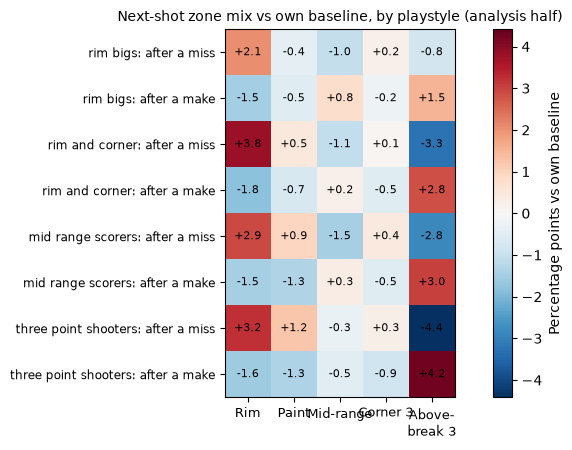

In [7]:
zm = st.zone_moves(d[d.cluster.notna()], "cluster").loc[CLUSTERS]
cols = ["rel_restricted_area", "rel_paint", "rel_mid_range", "rel_corner_three", "rel_above_break_three"]
fig, ax = plt.subplots(figsize=(8, 4.6))
lim = np.abs(zm[cols].to_numpy()).max()
im = ax.imshow(zm[cols].to_numpy(), cmap="RdBu_r", vmin=-lim, vmax=lim)
ax.set_xticks(range(5), ["Rim", "Paint", "Mid-range", "Corner 3", "Above-\nbreak 3"], fontsize=9)
ax.set_yticks(range(len(zm)), [f"{c.replace('_', ' ')}: {w}" for c, w in zm.index], fontsize=8.5)
for i in range(len(zm)):
    for j in range(5):
        ax.text(j, i, f"{zm[cols].iloc[i, j]:+.1f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="Percentage points vs own baseline")
ax.set_title("Next-shot zone mix vs own baseline, by playstyle (analysis half)", fontsize=10)
fig.tight_layout()
fig.savefig(FIGURES / "stage6_cluster_zones.png", dpi=150)
zm.round(2)

## 6. H4 descriptive check (not a test): high-usage share of all attempts, regular season vs playoffs

In [8]:
shots = pd.read_parquet(SHOTS, columns=["player_id", "season", "season_type", "half",
                                       "in_analysis_population"])
shots = shots[(shots.half == HALF) & shots.in_analysis_population]
tiers = pd.read_csv(PLAYER_SEASONS)[["player_id", "season", "season_type", "usage_tier"]]
s = shots.merge(tiers, on=["player_id", "season", "season_type"], how="left")
desc = s.groupby("season_type").usage_tier.apply(lambda t: (t == "high").mean() * 100).round(1)
desc.rename("high-usage share of attempts (%)")

season_type
Playoffs          65.6
Regular Season    55.8
Name: high-usage share of attempts (%), dtype: float64

## 7. Save

In [9]:
shifts["kind"] = "group shift"
tests["kind"] = "test"
holm_out = holm.rename(columns={"hypothesis": "test"}).assign(kind="holm")
secondary_out = secondary.rename(columns={"term": "test"}).assign(kind="secondary (not a finding)")
pairwise_out = pairwise.reset_index().rename(columns={"index": "test"}).assign(
    kind="H3 pairwise vs three-point shooters" + ("" if h3_rejects else " (not read: joint test does not reject)"))
desc_out = desc.reset_index().rename(columns={"usage_tier": "estimate", "season_type": "group"}).assign(
    kind="H4 descriptive: high-usage share of attempts (%)")
results = pd.concat([shifts, tests, holm_out, pairwise_out, secondary_out, desc_out], ignore_index=True)
results.insert(0, "half", HALF)
results.to_csv(PROCESSED / "results_segments.csv", index=False)
print(f"{len(results)} rows -> data/processed/results_segments.csv")

36 rows -> data/processed/results_segments.csv
